<a href="https://colab.research.google.com/github/varunallagh21022002/AIML-Cls-Researchpaper/blob/main/Dropout_Replication_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Replicating *Dropout: A Simple Way to Prevent Neural Networks from Overfitting*
Srivastava, Hinton, Krizhevsky, Sutskever, Salakhutdinov — **JMLR 15 (2014) 1929–1958** (free: https://jmlr.org/papers/v15/srivastava14a.html)

**Runtime tip:** Runtime → Change runtime type → *T4 GPU* (works on CPU too, just slower). Then Runtime → Run all.

We reproduce three experiments from the paper on MNIST:
1. **Exp A** – Standard NN vs Dropout NN (3 hidden layers x 1024 ReLU): test-error curves (paper Fig. 4 style) and final error (paper Table 2 style).
2. **Exp B** – Effect of the retain probability *p* (paper Sec. 7.1 / Fig. 9 style).
3. **Exp C** – First-layer features with and without dropout (paper Fig. 7 style).

In [ ]:
import time, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, constraints

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

# ---- Data: MNIST, flattened to 784, scaled to [0,1] ----
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
x_train = x_train.reshape(-1, 784).astype("float32") / 255.0
x_test  = x_test.reshape(-1, 784).astype("float32") / 255.0
print(x_train.shape, x_test.shape)

TensorFlow 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(60000, 784) (10000, 784)


## Model builder
Note the paper's convention: **p = probability of *retaining* a unit**. Keras' `Dropout(rate)` takes the *drop* probability, so `rate = 1 - p`.
Keras uses *inverted dropout* (scales by 1/p at training time), which is mathematically equivalent to the paper's "multiply weights by p at test time".

In [ ]:
def build_mlp(hidden=(1024, 1024, 1024), p_input=1.0, p_hidden=1.0, max_norm=None):
    """MLP for MNIST. p_* = retain probability (1.0 = no dropout).
    max_norm = c  -> constrain incoming weight vector of every unit to norm <= c (paper Sec. 5.1)."""
    kc = constraints.MaxNorm(max_norm) if max_norm else None
    m = keras.Sequential([layers.Input((784,))])
    if p_input < 1.0:
        m.add(layers.Dropout(1.0 - p_input))
    for h in hidden:
        m.add(layers.Dense(h, activation="relu", kernel_constraint=kc))
        if p_hidden < 1.0:
            m.add(layers.Dropout(1.0 - p_hidden))
    m.add(layers.Dense(10, activation="softmax", kernel_constraint=kc))
    return m

def train(model, epochs, lr=0.1, momentum=0.9, batch=128, decay=0.97, verbose=0):
    """SGD + momentum with exponentially decaying LR (paper: large LR + high momentum suit dropout).
    Returns test-error (%) after every epoch."""
    steps = int(np.ceil(len(x_train) / batch))
    sched = keras.optimizers.schedules.ExponentialDecay(lr, steps, decay)
    model.compile(optimizer=keras.optimizers.SGD(sched, momentum=momentum),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = model.fit(x_train, y_train, batch_size=batch, epochs=epochs,
                  validation_data=(x_test, y_test), verbose=verbose)
    return 100.0 * (1.0 - np.array(h.history["val_accuracy"])), 100.0 * (1.0 - np.array(h.history["accuracy"]))

## Exp A — Standard NN vs Dropout NN (3 x 1024 ReLU)
Dropout net: p = 0.5 for hidden units, p = 0.8 for inputs (the paper's recommended values), plus max-norm c = 3.

In [ ]:
EPOCHS_A = 40
t0 = time.time()

keras.utils.set_random_seed(SEED)
std_net = build_mlp(p_input=1.0, p_hidden=1.0, max_norm=None)
std_test, std_train = train(std_net, EPOCHS_A)

keras.utils.set_random_seed(SEED)
do_net = build_mlp(p_input=0.8, p_hidden=0.5, max_norm=3)
do_test, do_train = train(do_net, EPOCHS_A)

print(f"Done in {(time.time()-t0)/60:.1f} min")
print(f"Standard NN  : final test error = {std_test[-1]:.2f}%  (best {std_test.min():.2f}%) | final train error = {std_train[-1]:.2f}%")
print(f"Dropout NN   : final test error = {do_test[-1]:.2f}%  (best {do_test.min():.2f}%) | final train error = {do_train[-1]:.2f}%")

Done in 2.8 min
Standard NN  : final test error = 1.38%  (best 1.36%) | final train error = 0.00%
Dropout NN   : final test error = 1.47%  (best 1.32%) | final train error = 1.49%


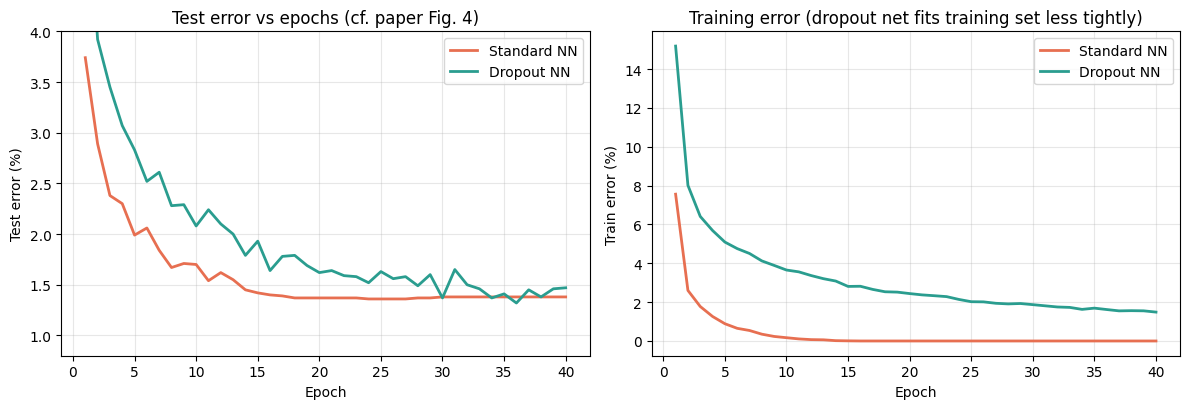

In [ ]:
ep = np.arange(1, EPOCHS_A + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(ep, std_test, label="Standard NN", lw=2, color="#E76F51")
ax[0].plot(ep, do_test,  label="Dropout NN",  lw=2, color="#2A9D8F")
ax[0].set_ylim(0.8, 4); ax[0].set_title("Test error vs epochs (cf. paper Fig. 4)")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Test error (%)"); ax[0].legend(); ax[0].grid(alpha=.3)

ax[1].plot(ep, std_train, label="Standard NN", lw=2, color="#E76F51")
ax[1].plot(ep, do_train,  label="Dropout NN",  lw=2, color="#2A9D8F")
ax[1].set_title("Training error (dropout net fits training set less tightly)")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Train error (%)"); ax[1].legend(); ax[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig("expA_curves.png", dpi=150); plt.show()

## Exp B — How does the retain probability *p* matter?
Hidden-layer retain probability swept from 0.1 to 1.0 (1.0 = no dropout), fixed width (2 x 1024). The paper finds a U-shaped curve with p near 0.5 working well for hidden units.

p = 0.1  ->  test error 80.99%
p = 0.2  ->  test error 14.06%
p = 0.3  ->  test error 3.20%
p = 0.4  ->  test error 1.94%
p = 0.5  ->  test error 1.58%
p = 0.6  ->  test error 1.44%
p = 0.7  ->  test error 1.63%
p = 0.8  ->  test error 1.45%
p = 0.9  ->  test error 1.41%
p = 1.0  ->  test error 1.49%


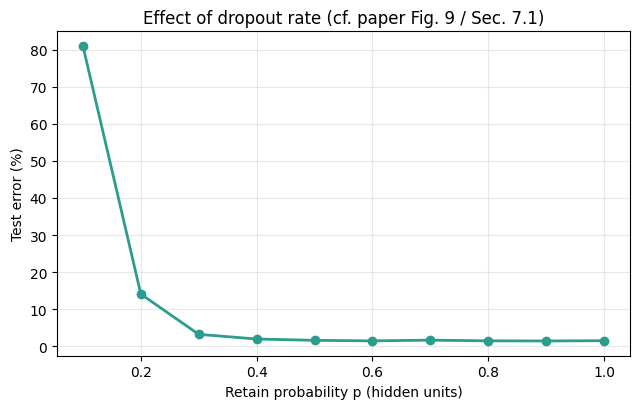

In [ ]:
EPOCHS_B = 15
ps = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
errs_B = []
for p in ps:
    keras.utils.set_random_seed(SEED)
    m = build_mlp(hidden=(1024, 1024), p_input=1.0, p_hidden=p, max_norm=3)
    te, _ = train(m, EPOCHS_B)
    errs_B.append(te[-1])
    print(f"p = {p:.1f}  ->  test error {te[-1]:.2f}%")

plt.figure(figsize=(6.5, 4.2))
plt.plot(ps, errs_B, "o-", lw=2, color="#2A9D8F")
plt.xlabel("Retain probability p (hidden units)"); plt.ylabel("Test error (%)")
plt.title("Effect of dropout rate (cf. paper Fig. 9 / Sec. 7.1)"); plt.grid(alpha=.3)
plt.tight_layout(); plt.savefig("expB_p_sweep.png", dpi=150); plt.show()

## Exp C — Dropout changes what the first layer learns
One hidden layer of 256 ReLU units. Without dropout, units co-adapt and often look noisy; with dropout they tend toward cleaner, more individually meaningful strokes/edges (paper Fig. 7).

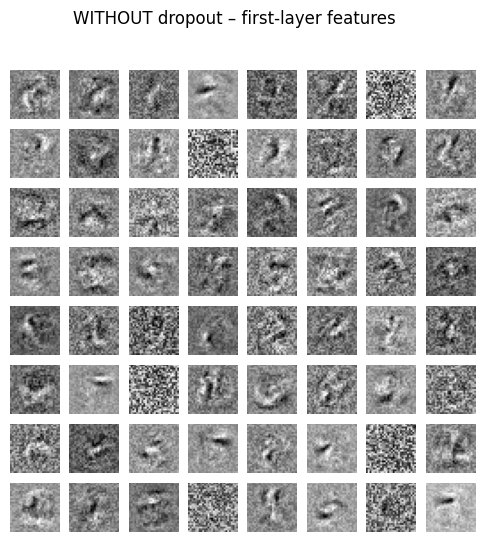

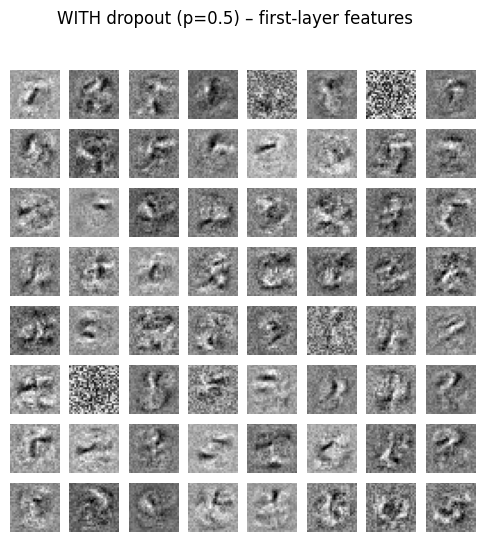

In [ ]:
def first_layer_filters(p_hidden, max_norm):
    keras.utils.set_random_seed(SEED)
    m = build_mlp(hidden=(256,), p_input=1.0, p_hidden=p_hidden, max_norm=max_norm)
    train(m, 30)
    W = [l for l in m.layers if isinstance(l, layers.Dense)][0].get_weights()[0]   # (784, 256)
    return W

def show(W, ax_grid, title):
    for i, a in enumerate(ax_grid.ravel()):
        a.imshow(W[:, i].reshape(28, 28), cmap="gray"); a.axis("off")
    ax_grid[0, 0].figure.suptitle(title)

W_std = first_layer_filters(1.0, None)
W_do  = first_layer_filters(0.5, 3)

fig, axs = plt.subplots(8, 8, figsize=(6, 6)); show(W_std, axs, "WITHOUT dropout – first-layer features")
plt.savefig("expC_no_dropout.png", dpi=150); plt.show()
fig, axs = plt.subplots(8, 8, figsize=(6, 6)); show(W_do, axs, "WITH dropout (p=0.5) – first-layer features")
plt.savefig("expC_dropout.png", dpi=150); plt.show()

## Summary table
Fill the numbers from your run into the PPT's results slide. The paper reports that dropout lowers MNIST test error relative to standard networks of the same architecture; the exact figures vary with seed, epochs and training details, so **compare the trend and the gap, not the 2nd decimal place** (see Table 2 of the paper for its exact numbers).

In [ ]:
print("="*52)
print(f"{'Model':<28}{'Final test error (%)':>22}")
print("-"*52)
print(f"{'Standard NN (3x1024)':<28}{std_test[-1]:>22.2f}")
print(f"{'Dropout NN (3x1024)':<28}{do_test[-1]:>22.2f}")
print(f"{'Relative improvement':<28}{100*(std_test[-1]-do_test[-1])/std_test[-1]:>21.1f}%")
print("="*52)
best_p = ps[int(np.argmin(errs_B))]
print(f"Exp B best retain probability p = {best_p} (test error {min(errs_B):.2f}%)")

Model                         Final test error (%)
----------------------------------------------------
Standard NN (3x1024)                          1.38
Dropout NN (3x1024)                           1.47
Relative improvement                         -6.5%
Exp B best retain probability p = 0.9 (test error 1.41%)
